# Метод опорных векторов

Метод опорных векторов ( Support Vector Machine, SVM) – это мощный алгоритм машинного обучения, способный выполнять линейную или нелинейную классификацию, регрессию и даже выявление выбросов.

В Sklearn метод опорных векторов реализован в модуле svm: https://scikit-learn.org/stable/api/sklearn.svm.html

***Какая из прямых разделяет классы лучше?***

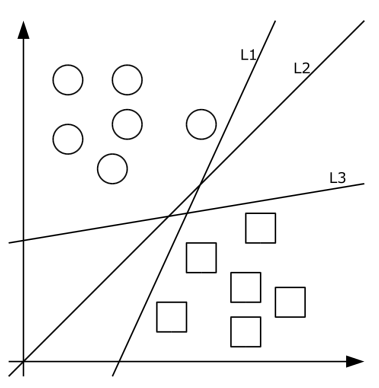

Основная идея метода опорных векторов заключается в поиске **границы решения** – гиперплоскости, разделяющей объекты на два множества, таким образом, чтобы расстояние между границей решения и самыми близкими к ней обучающими объектами (**опорными векторами**) была максимальной.
Две параллельных гиперплоскости строятся по обеим сторонам границы решения. Алгоритм работает в предположении, что чем больше расстояние между гиперплоскостями, тем меньше будет средняя ошибка классификатора, поэтому метод также называют методом классификации с максимальным зазором.

![img](https://habrastorage.org/webt/5s/g-/k9/5sg-k9ytduiqgxlsv66u6jprvsi.png)

![img](https://habrastorage.org/storage/habraeffect/41/27/41273d1e28d6b6c0b7c9a42eac2be771.png)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.svm import SVC  # Импортируем класс

Документация к SVC: https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html#sklearn.svm.SVC

Генерируем простые данные

In [2]:
X = np.array([[1, 2], [5, 8], [1.5, 1.8], [8, 8], [1, 0.6], [9, 11]])

In [3]:
y = [0, 1, 0, 1, 0, 1]

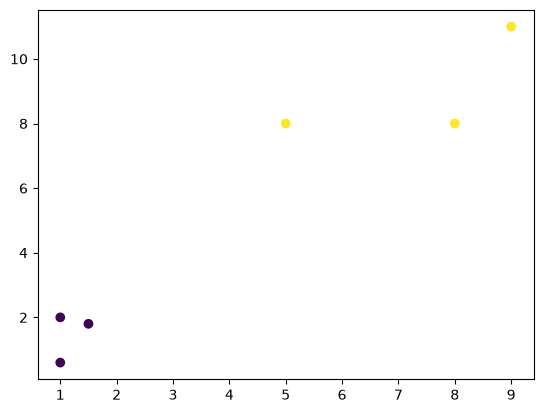

In [4]:
plt.scatter(X[:, 0], X[:, 1], c=y)

In [5]:
clf = SVC(kernel="linear")  # Создаем экземпляр класса
clf.fit(X, y)  # Обучаем

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


[0.1380943  0.24462418]


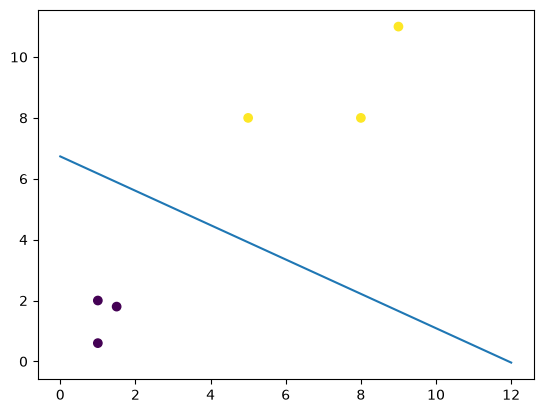

In [6]:
w = clf.coef_[0]
print(w)
a = -w[0] / w[1]
xx = np.linspace(0, 12)
yy = a * xx - clf.intercept_[0] / w[1]

h0 = plt.plot(xx, yy)
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.show()

<a href="https://ibb.co/pxvfjgm"><img src="https://i.ibb.co/L8zxdMG/3.jpg" alt="3" border="0"></a>

## Классификация с мягким зазором (soft-margin SVM)

Цель заключается в том, чтобы отыскать хороший баланс между удержанием полосы как можно более широкой и ограничением количества нарушений зазора (т.е. появления экземпляров, которые оказываются посредине полосы или даже на неправильной стороне).

В классах SVM библиотеки Scikit-Learn вы можете управлять упомянутым балансом, используя гиперпараметр C: меньшее значение C ведет к более широкой полосе, но большему числу нарушений зазора.

![img](https://www.bogotobogo.com/python/scikit-learn/images/svm/bias-variance-trade-off-svm.png)

## Решение нелинейных задач ядерным методом SVM

Ключевая идея в основе ядерных методов остоит в том, чтобы спроецировать данные на пространство
более высокой размерности, где они становятся линейно разделимыми.   
Как показано на нижеследующем рисунке, мы можем трансформировать двумерный набор данных в новое трехмерное пространство признаков, где классы становятся разделимыми.

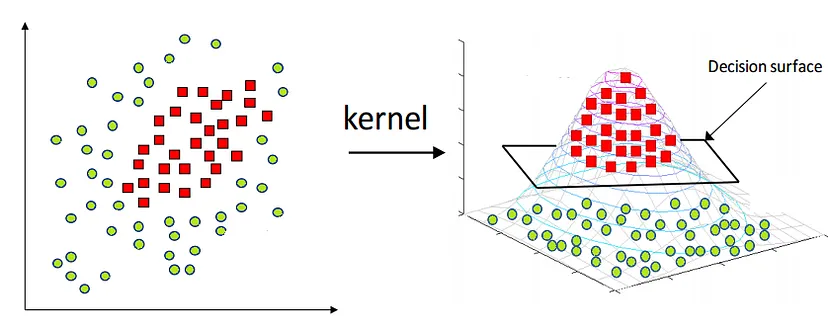

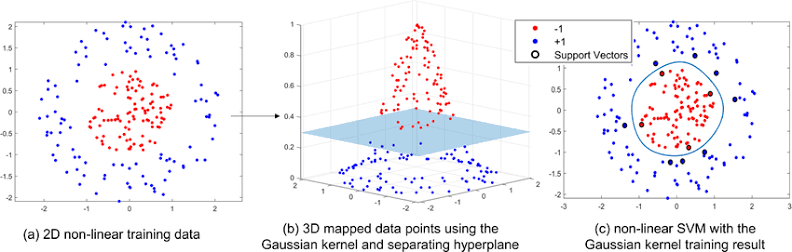

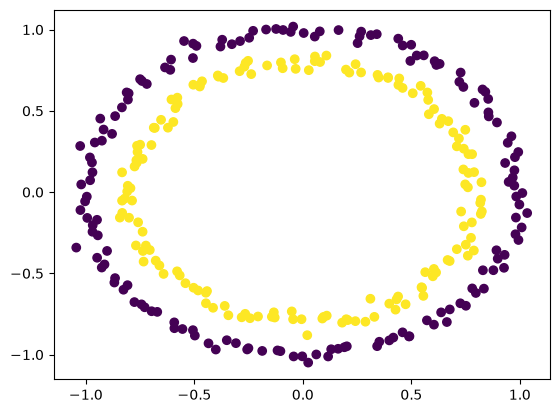

In [9]:
from sklearn.datasets import make_circles

X, y = make_circles(n_samples=300, noise=0.03)  # Сгенерируем данные

plt.scatter(X[:, 0], X[:, 1], c=y)

In [10]:
clf = SVC(kernel="linear")  # Создаем экземпляр класса
clf.fit(X, y)  # Обучаем
clf.score(X, y)  # Оценим долю правильных ответов

0.5

In [11]:
clf = SVC(kernel="rbf")  # Создаем экземпляр класса
clf.fit(X, y)  # Обучаем
clf.score(X, y)  # Оценим долю правильных ответов

1.0

##  Пример на датасете Ionosphere

Данные собраны системой фазированных антенн в Гуз-Бей (Лабрадор, Канада). Система состояла из 16 высокочастотных антенн с общей мощностью около 6,4 кВт. Целью зондирования были свободные электроны в ионосфере.

Отражённые сигналы обрабатывались автокорреляционной функцией, аргументами которой были время импульса и номер импульса. В системе использовалось 17 номеров импульсов, и для каждого импульса записывалось 2 атрибута, соответствующих комплексным значениям электромагнитного сигнала. Итого: 17 х 2 = 34 признака. 34 признака — это не набор разнородных характеристик, а структурированное представление одного сложного сигнала, разложенного на 17 временных отсчетов, каждый из которых описан двумя компонентами.

**Целевая переменная** представлена так:
* Хороший сигнал "Good" — сигнал показывает наличие некоторой структуры в ионосфере (то есть сигнал отразился от слоя с электронной плотностью).

* Плохой сигнал "Bad" — сигнал не показывает структуры; он просто прошёл сквозь ионосферу.

В исходном датасете метки закодированы как 'g' и 'b', распределение классов	225 "good" и 126 "bad" (примерно 64% / 36%)

Загрузим данные и посмотрим на характеристики датасета

In [12]:
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    f1_score,
)  # ,
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# balanced_accuracy_score)

# Загружаем датасет Ionosphere напрямую из UCI
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/ionosphere/ionosphere.data"
column_names = [f"feature_{i}" for i in range(34)] + ["label"]
df = pd.read_csv(url, names=column_names)

print("Размер данных:", df.shape)
print("Распределение классов:\n", df["label"].value_counts())


Размер данных: (351, 35)
Распределение классов:
 label
g    225
b    126
Name: count, dtype: int64


In [13]:
df.head()

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_25,feature_26,feature_27,feature_28,feature_29,feature_30,feature_31,feature_32,feature_33,label
0,1,0,0.99539,-0.05889,0.85243,0.02306,0.83398,-0.37708,1.00000,0.03760,...,-0.51171,0.41078,-0.46168,0.21266,-0.34090,0.42267,-0.54487,0.18641,-0.45300,g
1,1,0,1.00000,-0.18829,0.93035,-0.36156,-0.10868,-0.93597,1.00000,-0.04549,...,-0.26569,-0.20468,-0.18401,-0.19040,-0.11593,-0.16626,-0.06288,-0.13738,-0.02447,b
2,1,0,1.00000,-0.03365,1.00000,0.00485,1.00000,-0.12062,0.88965,0.01198,...,-0.40220,0.58984,-0.22145,0.43100,-0.17365,0.60436,-0.24180,0.56045,-0.38238,g
3,1,0,1.00000,-0.45161,1.00000,1.00000,0.71216,-1.00000,0.00000,0.00000,...,0.90695,0.51613,1.00000,1.00000,-0.20099,0.25682,1.00000,-0.32382,1.00000,b
4,1,0,1.00000,-0.02401,0.94140,0.06531,0.92106,-0.23255,0.77152,-0.16399,...,-0.65158,0.13290,-0.53206,0.02431,-0.62197,-0.05707,-0.59573,-0.04608,-0.65697,g


Определим независимые и целевую переменные

In [14]:
X = df.drop("label", axis=1).values
y = LabelEncoder().fit_transform(df["label"])  # 'g' -> 0, 'b' -> 1

Разделение данных на обучающие и тестовые + масштабирование

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Обучим модель с линейным и RBF-ядрами

In [16]:
results = {}

for kernel in ["linear", "rbf"]:
    clf = SVC(kernel=kernel, C=1.0, gamma="scale", random_state=42)
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)

    results[kernel] = {
        "f1_macro": f1_score(y_test, y_pred, average="macro"),
        "model": clf,
        "y_pred": y_pred,
    }

    print(f"=== {kernel.upper()} ===")
    print(f"F1-score:          {results[kernel]['f1_macro']:.3f}")
    print()

=== LINEAR ===
F1-score:          0.887

=== RBF ===
F1-score:          0.924



Все метрики

In [17]:
for kernel in ["linear", "rbf"]:
    print(f"=== {kernel.upper()} ===")
    print(
        classification_report(
            y_test,
            results[kernel]["y_pred"],
            target_names=['Класс "хороший"', 'Класс "плохой"'],
        )
    )

=== LINEAR ===
                 precision    recall  f1-score   support

Класс "хороший"       0.90      0.81      0.85        32
 Класс "плохой"       0.90      0.95      0.92        56

       accuracy                           0.90        88
      macro avg       0.90      0.88      0.89        88
   weighted avg       0.90      0.90      0.90        88

=== RBF ===
                 precision    recall  f1-score   support

Класс "хороший"       0.96      0.84      0.90        32
 Класс "плохой"       0.92      0.98      0.95        56

       accuracy                           0.93        88
      macro avg       0.94      0.91      0.92        88
   weighted avg       0.93      0.93      0.93        88



Матрица ошибок

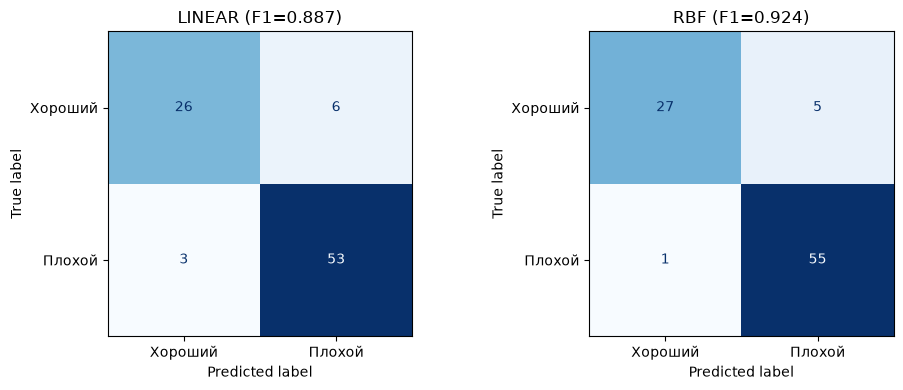

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, kernel in zip(axes, ["linear", "rbf"]):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        results[kernel]["y_pred"],
        display_labels=["Хороший", "Плохой"],
        ax=ax,
        cmap="Blues",
        colorbar=False,
    )
    ax.set_title(f"{kernel.upper()} (F1={results[kernel]['f1_macro']:.3f})")

plt.tight_layout()
plt.show()

Видно, что RBF выигрывает в точности классификации у линейного ядра.

### Визуализация границы решения (через два признака)

Попробуем оценить результаты классификации для двумерной проекции

Смотрим, какие признаки вообще варьируются


In [19]:
variances = X_train.var(axis=0)
top_features = np.argsort(variances)[-5:]  # 5 самых "живых" признаков
print("Индексы признаков с наибольшей дисперсией:", top_features)
print("Их дисперсии:", variances[top_features])

Индексы признаков с наибольшей дисперсией: [ 8 16  6 28 26]
Их дисперсии: [1. 1. 1. 1. 1.]


Берём два самых информативных

In [20]:
f1, f2 = top_features[-1], top_features[-2]
print(f"Используем признаки {f1} и {f2}")

Используем признаки 26 и 28


Проводим обучение модели с линейным и RBF-ядрами и визуализацию

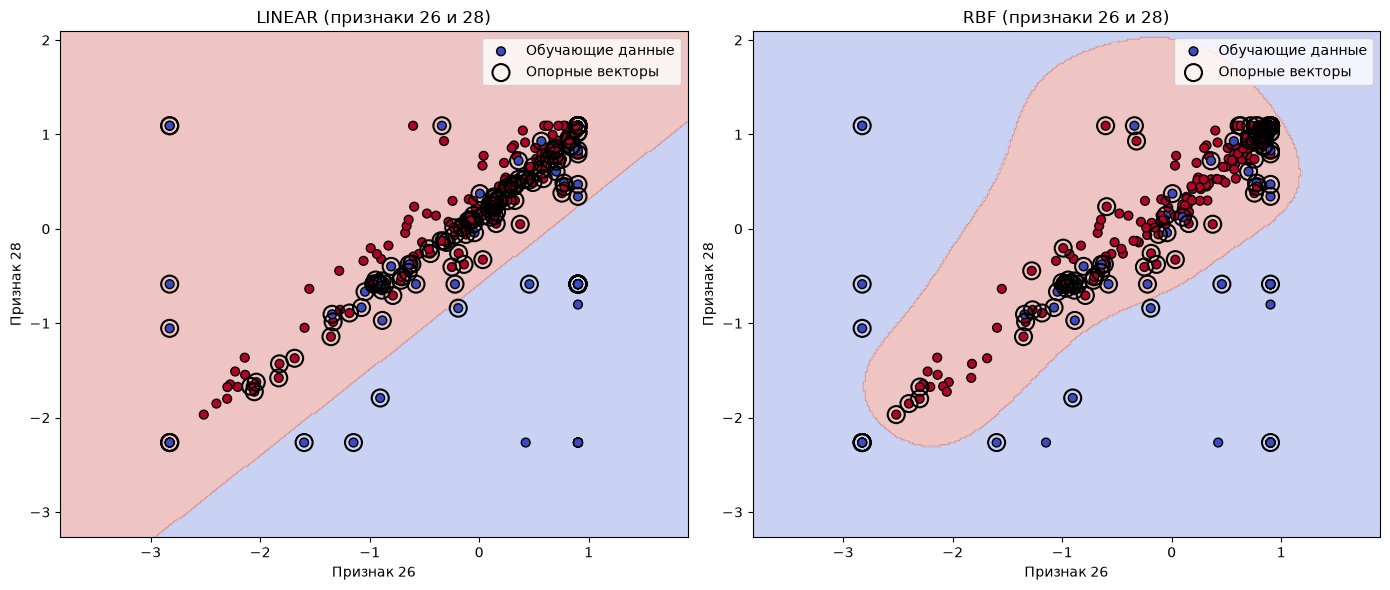

In [21]:
X_vis = X_train[:, [f1, f2]]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, kernel in zip(axes, ["linear", "rbf"]):
    current_gamma = "scale" if kernel == "linear" else 1.0

    clf_2d = SVC(kernel=kernel, C=1.0, gamma=current_gamma, random_state=42)
    clf_2d.fit(X_vis, y_train)

    x_min, x_max = X_vis[:, 0].min() - 1, X_vis[:, 0].max() + 1
    y_min, y_max = X_vis[:, 1].min() - 1, X_vis[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    Z = clf_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm", zorder=1)
    ax.scatter(
        X_vis[:, 0],
        X_vis[:, 1],
        c=y_train,
        cmap="coolwarm",
        edgecolors="k",
        s=40,
        zorder=2,
        label="Обучающие данные",
    )
    ax.scatter(
        clf_2d.support_vectors_[:, 0],
        clf_2d.support_vectors_[:, 1],
        s=150,
        facecolors="none",
        edgecolors="k",
        linewidths=1.5,
        zorder=3,
        label="Опорные векторы",
    )

    ax.set_title(f"{kernel.upper()} (признаки {f1} и {f2})")
    ax.set_xlabel(f"Признак {f1}")
    ax.set_ylabel(f"Признак {f2}")
    ax.legend()

plt.tight_layout()
plt.show()

### Что показывает график


1. Линейное ядро — прямая диагональная граница. Она режет данные грубо, но не может обойти "языки" одного класса, вторгающиеся в другой.

2. RBF-ядро — изогнутая граница, которая огибает плотное скопление красных точек. Это наглядно демонстрирует главную идею: RBF умеет строить нелинейные разделяющие поверхности.

3. Опорные векторы (кружки) — лежат по обе стороны от границы. Это те точки, которые её "держат".

**Важный нюанс**: обратите внимание, что на двумерной проекции классы сильно перемешаны. Красные точки (класс "хороший") образуют узкую полосу, но в неё вторгаются синие, и наоборот. Это нормально, потому что:

* Мы взяли только 2 признака из 34. Остальные 32 содержат информацию, которая в этой проекции не видна.

* На 2D-графике линейная и RBF границы выглядят "похоже по качеству" — обе ошибаются.

* Но при обучении на всех 34 признаках RBF даёт F1-macro = 0.92 против 0.89 у линейного. Разница в 3% — и она реальна.

**Вывод**: визуализация в 2D — это концептуальная иллюстрация, а не доказательство. Она показывает форму границы, но не реальное качество модели. Настоящее качество измеряется на полной размерности через метрики.